# Steam Review Complaint Classification

**Question:** What do Steam players complain about, and which games and publishers get the most complaints?

**Data:** 20,000 player reviews from the Kaggle *Gaming Profiles* dataset (Steam subset), loaded via BigQuery.

**Approach**
1. Keep English reviews only (language detection)
2. Detect complaints and their categories (Bug, Crash, Update, Price, Server, Lag, DLC, Cheater) with rules
3. Measure the rules against **manually labelled** reviews, improve them, and test on a held-out set
4. Check whether an ML model trained on the rule labels adds value
5. Turn the labels into game and publisher level insights

**Key results (held-out test set, 150 reviews)**

| Method | Complaint detection F1 | Category micro-F1 |
|---|---|---|
| v1 – original keyword rules | 0.62 | 0.46 |
| **v3 – improved rules** | **0.72** | **0.58** |
| TF-IDF + Logistic Regression (trained on v3 labels) | 0.67 | 0.48 |

About **10%** of English reviews contain a complaint. Complaint rates range from ~5% (Valve) to ~31% (KRAFTON / PUBG).

> This notebook is version 2 of the analysis. Version 1 had a broken language filter and keyword
> labels that also caught positive reviews; sections 2–3 show those problems and how they were fixed.

## 0. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("..").resolve()          # repository root (this notebook lives in notebooks/)
DATA_DIR = ROOT / "data"
IMAGES_DIR = ROOT / "images"

sys.path.insert(0, str(ROOT / "src"))
from complaint_rules import CATEGORIES, complaints_v1, complaints_v3

RANDOM_STATE = 42
pd.set_option("display.max_colwidth", 120)

## 1. Load the data

The raw review data is not stored in the repo (size + licence). See [`data/README.md`](../data/README.md):
either place the 20,000-review export at `data/reviews_sample_20k.csv`, or put the full Kaggle `reviews.csv`
in `data/` and the exact same sample is rebuilt from `data/sample_review_ids.csv`.

In [2]:
sample_path = DATA_DIR / "reviews_sample_20k.csv"

if sample_path.exists():
    df = pd.read_csv(sample_path)
else:
    sample_ids = pd.read_csv(DATA_DIR / "sample_review_ids.csv")
    full = pd.read_csv(DATA_DIR / "reviews.csv")
    df = full[full["reviewid"].isin(sample_ids["reviewid"])].copy()

df["review"] = df["review"].fillna("").astype(str)

print(df.shape)
df.head(3)

(20000, 8)


,reviewid,playerid,gameid,review,helpful,funny,awards,posted
0,1122946,76561197990186597,18500,This game is smashing.,0,0,0,2010-10-19
1,1033974,76561197989169398,62100,This is one of them good time killer games to play while going on a trip. Plus you are donating while getting a fun ...,0,0,0,2010-11-19
2,1141134,76561197990713373,440,This game was better before Gabe Newell started to ask people to buy stuff so he can haz afford sandvich big time,0,0,0,2010-11-19


## 2. Language filter

### 2.1 The bug in version 1

Version 1 built the detector with **only English** as a candidate. `lingua` picks the most likely language
*among the candidates it is given*, so with one candidate every Latin-script text becomes "English";
only Cyrillic or Chinese reviews were filtered out.

In [3]:
from lingua import Language, LanguageDetectorBuilder

english_only = LanguageDetectorBuilder.from_languages(Language.ENGLISH).build()

examples = [
    "Keine Gute Steuerung und Dualshock 3 funktioniert nicht.",
    "Bien pour les personnes patientes ^^",
    "Muito divertido. é mais para quem gosta",
    "Отличная игра, всем советую!",
]

for text in examples:
    print(f"{str(english_only.detect_language_of(text)):18} | {text}")

Language.ENGLISH   | Keine Gute Steuerung und Dualshock 3 funktioniert nicht.
Language.ENGLISH   | Bien pour les personnes patientes ^^
Language.ENGLISH   | Muito divertido. é mais para quem gosta
None               | Отличная игра, всем советую!


### 2.2 The fix

Give the detector the languages that actually appear in Steam reviews, so it can compare English with them.
A curated list works better than all 75 languages: with every language as a candidate, short English
reviews like *"Amazing game!"* were detected as Zulu or Norwegian.

In [4]:
STEAM_LANGUAGES = [
    Language.ENGLISH, Language.PORTUGUESE, Language.SPANISH, Language.GERMAN,
    Language.FRENCH, Language.TURKISH, Language.POLISH, Language.RUSSIAN,
    Language.ITALIAN, Language.DUTCH, Language.SWEDISH, Language.DANISH,
    Language.BOKMAL, Language.FINNISH, Language.CZECH, Language.HUNGARIAN,
    Language.ROMANIAN, Language.UKRAINIAN, Language.CHINESE, Language.JAPANESE,
    Language.KOREAN, Language.THAI,
]

detector = LanguageDetectorBuilder.from_languages(*STEAM_LANGUAGES).build()


def detect_language(text):
    text = text.strip()

    if len(text) < 3:          # "5", ":)" -> language cannot be determined
        return None

    language = detector.detect_language_of(text)
    return language.name if language else None


df["language"] = df["review"].apply(detect_language)
df["english_v1"] = df["review"].apply(lambda t: english_only.detect_language_of(t) == Language.ENGLISH)

print("v1 'English' reviews:", df["english_v1"].sum())
print("v2 English reviews:  ", (df["language"] == "ENGLISH").sum())

v1 'English' reviews: 12158
v2 English reviews:   11176


In [5]:
leaked = df[df["english_v1"] & (df["language"] != "ENGLISH")]
dropped = df[~df["english_v1"] & (df["language"] == "ENGLISH")]

print(f"Kept by v1 but not English: {len(leaked)}")
print(f"English but dropped by v1:  {len(dropped)}")
leaked["language"].value_counts().head(8)

Kept by v1 but not English: 2722
English but dropped by v1:  1740


language
PORTUGUESE    787
SPANISH       466
GERMAN        342
FRENCH        265
TURKISH       262
ITALIAN       122
POLISH        113
RUSSIAN        98
Name: count, dtype: int64

In [6]:
# v1 also dropped short English reviews: with a single candidate language,
# lingua returns None when it is not confident enough
dropped["review"].sample(5, random_state=RANDOM_STATE).tolist()

['Cool little game, would like to see more levels!',
 'GOOD GAME',
 "can't play online wtf",
 'Cool game ;)',
 'Nice game !!!']

In [7]:
en = df[df["language"] == "ENGLISH"].copy()
en.shape

(11176, 10)

**Finding:** version 1 had two errors that partly cancelled out in the total count:
- it **kept 2,722 non-English reviews** (22% of its "English" set), mostly Portuguese, Spanish, German, French and Turkish
- it **dropped 1,740 short English reviews** (*"Great game"*, *"awesome game!"*)

Language detection on 1–3 word reviews stays somewhat noisy; that is accepted here.

## 3. Complaint labels

### 3.1 Why the version 1 rules fail

Version 1 checked whether a keyword appears *anywhere inside* the lowercased text, and the first matching
category won. Some reviews it labels as complaints:

In [8]:
tricky = [
    "Amazing game, no bugs and no problems at all!",
    "Great hack and slash game",
    "Beautiful village and a cool flag system",
    "Love the costume options",
    "Runs perfectly, great performance",
    "Best update ever, the devs are amazing",
    "Good game but the servers are terrible.",
]

for text in tricky:
    print(f"{str(complaints_v1(text)):12} | {text}")

['Bug']      | Amazing game, no bugs and no problems at all!
['Cheater']  | Great hack and slash game
['Lag']      | Beautiful village and a cool flag system
['Price']    | Love the costume options
['Lag']      | Runs perfectly, great performance
['Update']   | Best update ever, the devs are amazing
['Server']   | Good game but the servers are terrible.


Four problems:
- **Substring matches:** `"lag"` is inside *village* and *flag*, `"cost"` inside *costume*
- **No negation:** *"no bugs"* becomes Bug
- **No sentiment:** praise (*"best update ever"*) becomes a complaint
- **Single label + order:** a review with bug *and* server complaints is always Bug, which inflates Bug

### 3.2 Version 3 rules

Full code: [`src/complaint_rules.py`](../src/complaint_rules.py). The design:

| Idea | Example |
|---|---|
| Whole-word regex (`\b`) | *village* no longer matches `lag` |
| Negation check (up to 2 words before) | *no bugs*, *never had any crashes* are skipped |
| Split into sentences and around *but / however / although* | *"Great game **but** the servers are terrible"* judges the second clause alone |
| **Strong** words count on their own | *bug, crash, lag, hacker, pay to win* |
| **Weak** words count only in a negative clause (VADER sentiment ≤ −0.05) | *update, price, server, DLC, performance* |
| Multi-label | one review can be Bug + Server |

A version 2 (sentiment check on *every* match) was also tried: it was precise but missed half of the
complaints, because a complaint inside a positive sentence (*"Good game but full of bugs"*) scores positive.
That error analysis led to the strong/weak split.

In [9]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

vader = SentimentIntensityAnalyzer()


def sentiment(text):
    return vader.polarity_scores(text)["compound"]


for text in tricky:
    print(f"{str(complaints_v3(text, sentiment)):12} | {text}")

[]           | Amazing game, no bugs and no problems at all!
[]           | Great hack and slash game
[]           | Beautiful village and a cool flag system
[]           | Love the costume options
[]           | Runs perfectly, great performance
[]           | Best update ever, the devs are amazing
['Server']   | Good game but the servers are terrible.


In [10]:
en["v1"] = en["review"].apply(complaints_v1)
en["v3"] = en["review"].apply(lambda t: complaints_v3(t, sentiment))

print("Reviews flagged as complaints")
print("  v1:", (en["v1"].str.len() > 0).sum())
print("  v3:", (en["v3"].str.len() > 0).sum())

Reviews flagged as complaints
  v1: 1892
  v3: 1142


## 4. Measuring against manual labels

Rule labels are not ground truth, so the methods are scored against reviews read and labelled by hand
(files in [`data/labels/`](../data/labels/)).

- **Dev set – 200 reviews:** used for error analysis while designing the v3 rules
- **Test set – 150 reviews:** labelled separately and **never looked at while writing rules**; this is the honest score

Each set mixes random reviews with reviews flagged by any rule version, so it contains enough complaints to
measure. A category is labelled when the review complains about it, even inside a positive review.

In [11]:
def load_labels(name):
    labels = pd.read_csv(DATA_DIR / "labels" / f"{name}_labels.csv")
    labels["labels"] = labels["labels"].fillna("").apply(lambda s: [x for x in s.split("|") if x])
    return labels.merge(en[["reviewid", "review", "v1", "v3"]], on="reviewid")


dev = load_labels("dev")
test = load_labels("test")

for name, labelled in [("dev", dev), ("test", test)]:
    random_part = labelled[labelled["pool"] == "random"]
    rate = (random_part["labels"].str.len() > 0).mean()
    print(f"{name}: {len(labelled)} reviews, complaint rate in the random part = {rate:.0%}")

dev: 200 reviews, complaint rate in the random part = 9%
test: 150 reviews, complaint rate in the random part = 6%


Two levels of scoring:
- **Complaint detection:** does the review contain *any* complaint? (precision, recall, F1)
- **Categories:** are the right categories found? micro-F1 pools all decisions; macro-F1 averages the 8 categories equally

In [12]:
from sklearn.metrics import precision_recall_fscore_support
from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer(classes=CATEGORIES)
mlb.fit([CATEGORIES])


def score(true_labels, predicted_labels):
    y_true = mlb.transform(true_labels)
    y_pred = mlb.transform(predicted_labels)

    p, r, f1, _ = precision_recall_fscore_support(
        y_true.any(axis=1), y_pred.any(axis=1), average="binary", zero_division=0
    )
    _, _, micro_f1, _ = precision_recall_fscore_support(y_true, y_pred, average="micro", zero_division=0)
    _, _, macro_f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)

    return {
        "complaint precision": p,
        "complaint recall": r,
        "complaint F1": f1,
        "category micro-F1": micro_f1,
        "category macro-F1": macro_f1,
    }

## 5. Can a model beat the rules?

Version 1 trained TF-IDF + Logistic Regression on rule labels **and only on reviews that already had a
complaint**, so the model never saw a normal review. Here the model is trained on all English reviews
(except the 350 labelled ones), one binary classifier per category, with balanced class weights.

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

labelled_ids = set(dev["reviewid"]) | set(test["reviewid"])
train = en[~en["reviewid"].isin(labelled_ids)]

vectorizer = TfidfVectorizer(
    max_features=20_000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True,
)

model = OneVsRestClassifier(
    LogisticRegression(max_iter=2000, class_weight="balanced", C=4)
)

model.fit(
    vectorizer.fit_transform(train["review"]),
    mlb.transform(train["v3"]),
)


def predict_model(texts, threshold=0.5):
    probabilities = model.predict_proba(vectorizer.transform(texts))
    return [
        [category for category, p in zip(CATEGORIES, row) if p >= threshold]
        for row in probabilities
    ]


test["model"] = predict_model(test["review"])
dev["model"] = predict_model(dev["review"])

## 6. Results

In [14]:
METHODS = {
    "v1 – original rules": "v1",
    "v3 – improved rules": "v3",
    "TF-IDF + LR (v3 labels)": "model",
}

results = pd.DataFrame(
    {
        (set_name, method): score(labelled["labels"], labelled[column])
        for set_name, labelled in [("dev", dev), ("test", test)]
        for method, column in METHODS.items()
    }
).T.round(2)

results

complaint precision  complaint recall  \
dev  v1 – original rules                     0.51              0.93   
     v3 – improved rules                     0.67              0.70   
     TF-IDF + LR (v3 labels)                 0.69              0.63   
test v1 – original rules                     0.48              0.85   
     v3 – improved rules                     0.67              0.78   
     TF-IDF + LR (v3 labels)                 0.75              0.61   

                              complaint F1  category micro-F1  \
dev  v1 – original rules              0.66               0.45   
     v3 – improved rules              0.68               0.58   
     TF-IDF + LR (v3 labels)          0.66               0.48   
test v1 – original rules              0.62               0.46   
     v3 – improved rules              0.72               0.58   
     TF-IDF + LR (v3 labels)          0.67               0.48   

                              category macro-F1  
dev  v1 – original rules                   0.42  
     v3 – improved rules                   0.49  
     TF-IDF + LR (v3 labels)               0.48  
test v1 – original rules                   0.37  
     v3 – improved rules                   0.48  
     TF-IDF + LR (v3 labels)               0.37

In [15]:
y_true = mlb.transform(test["labels"])
y_pred = mlb.transform(test["v3"])
p, r, f1, support = precision_recall_fscore_support(y_true, y_pred, zero_division=0)

pd.DataFrame(
    {"precision": p, "recall": r, "F1": f1, "reviews": support},
    index=CATEGORIES,
).round(2).sort_values("reviews", ascending=False)

,precision,recall,F1,reviews
Bug,0.56,0.75,0.64,20
Lag,0.82,0.60,0.69,15
Price,0.67,0.57,0.62,14
Update,0.50,0.20,0.29,5
DLC,0.75,0.60,0.67,5
Crash,0.50,1.00,0.67,4
Server,0.00,0.00,0.00,3
Cheater,0.14,1.00,0.25,1


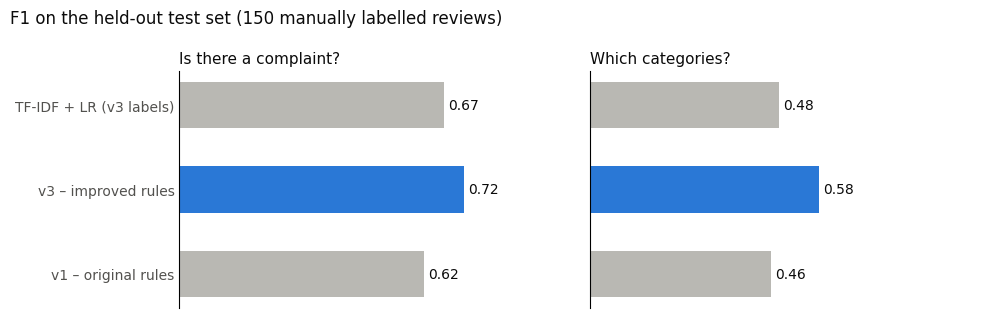

In [16]:
BLUE, GREY = "#2a78d6", "#b9b8b3"
INK, MUTED = "#0b0b0b", "#52514e"

test_scores = results.loc["test"]
metrics = ["complaint F1", "category micro-F1"]
titles = ["Is there a complaint?", "Which categories?"]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)

for ax, metric, title in zip(axes, metrics, titles):
    values = test_scores[metric]
    colors = [BLUE if name.startswith("v3") else GREY for name in values.index]

    ax.barh(values.index, values.values, color=colors, height=0.55)
    for y, v in enumerate(values.values):
        ax.text(v + 0.01, y, f"{v:.2f}", va="center", color=INK, fontsize=10)

    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.set_xlim(0, 1)
    ax.invert_yaxis()
    ax.tick_params(colors=MUTED, length=0)
    ax.spines[["top", "right", "bottom"]].set_visible(False)
    ax.set_xticks([])

fig.suptitle("F1 on the held-out test set (150 manually labelled reviews)", x=0.01, ha="left", color=INK)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "03_method_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

**Reading the results**
- **v3 is the best method on both levels**, and its test score (0.72) is as good as its dev score (0.68),
  so the rules were not just fitted to the reviews used to design them.
- **v1 has high recall but low precision:** it finds most complaints, but about half of what it flags is not a complaint.
- **The model does not beat the rules it learned from.** Trained on rule labels, it can only imitate the rules,
  and it misses part of them. To add value, a model needs human labels as training data (next steps).
- Weakest categories: **Server** and **Update** (few examples, and these words are often neutral).
- The test set is small (150 reviews, 54 with complaints), so differences of a few points are not meaningful.

## 7. Insights: what do players complain about?

v3 rules applied to all English reviews. Game titles and publishers come from `games.csv` of the same dataset.
Rates use rule labels (precision ≈ 0.67), so treat them as estimates and compare games with each other.

In [17]:
import ast

games = pd.read_csv(DATA_DIR / "games.csv", usecols=["gameid", "title", "publishers"])


def first_publisher(value):
    try:
        return ast.literal_eval(value)[0]
    except (ValueError, SyntaxError, IndexError):
        return None


games["publisher"] = games["publishers"].apply(first_publisher)

en = en.merge(games[["gameid", "title", "publisher"]], on="gameid", how="left")
en["has_complaint"] = en["v3"].str.len() > 0

print(f"Reviews with a complaint: {en['has_complaint'].mean():.1%}")

Reviews with a complaint: 10.2%


In [18]:
category_share = (
    en["v3"].explode().value_counts() / en["has_complaint"].sum()
).rename("share of complaint reviews")

category_share.round(3)

v3
Bug        0.517
Lag        0.160
Crash      0.136
Cheater    0.134
Price      0.110
Server     0.091
DLC        0.084
Update     0.037
Name: share of complaint reviews, dtype: float64

In [19]:
MIN_REVIEWS = 40

by_game = (
    en.groupby("title")
    .agg(reviews=("reviewid", "size"), complaint_rate=("has_complaint", "mean"))
    .query("reviews >= @MIN_REVIEWS")
    .sort_values("complaint_rate", ascending=False)
)


def top_category(title):
    counts = en.loc[en["title"] == title, "v3"].explode().value_counts()
    return counts.index[0] if len(counts) else "–"


by_game["top_complaint"] = [top_category(t) for t in by_game.index]
by_game.head(10).round(3)

,reviews,complaint_rate,top_complaint
title,,,
ARK: Survival Evolved,52,0.327,Lag
PUBG: BATTLEGROUNDS,112,0.312,Bug
Fallout 4,43,0.279,Bug
DayZ,71,0.225,Bug
Z1 Battle Royale,49,0.204,Bug
Grand Theft Auto V,109,0.193,Cheater
Tom Clancy's Rainbow Six® Siege,42,0.190,Server
Rust,89,0.135,Bug
PAYDAY 2,141,0.113,DLC


In [20]:
by_publisher = (
    en.groupby("publisher")
    .agg(reviews=("reviewid", "size"), complaint_rate=("has_complaint", "mean"))
    .query("reviews >= 100")
    .sort_values("complaint_rate", ascending=False)
)

by_publisher.round(3)

,reviews,complaint_rate
publisher,,
"KRAFTON, Inc.",112,0.312
Activision,129,0.202
Rockstar Games,166,0.163
Bethesda Softworks,381,0.155
Bohemia Interactive,124,0.153
Ubisoft,217,0.152
Starbreeze Publishing AB,141,0.113
Square Enix,150,0.107
2K,325,0.105


In [21]:
# Complaint mix for the most-reviewed games
most_reviewed = en["title"].value_counts().head(5).index

(
    en[en["title"].isin(most_reviewed)]
    .explode("v3")
    .dropna(subset=["v3"])
    .pivot_table(index="title", columns="v3", values="reviewid", aggfunc="count", fill_value=0)
)

v3,Bug,Cheater,Crash,DLC,Lag,Price,Server,Update
title,,,,,,,,
Counter-Strike 2,13,53,1,1,8,5,6,3
Dota 2,4,1,1,0,0,1,2,0
Garry's Mod,6,0,1,0,0,1,4,1
PAYDAY 2,5,2,3,8,2,1,2,3
Team Fortress 2,6,1,0,1,3,1,4,4


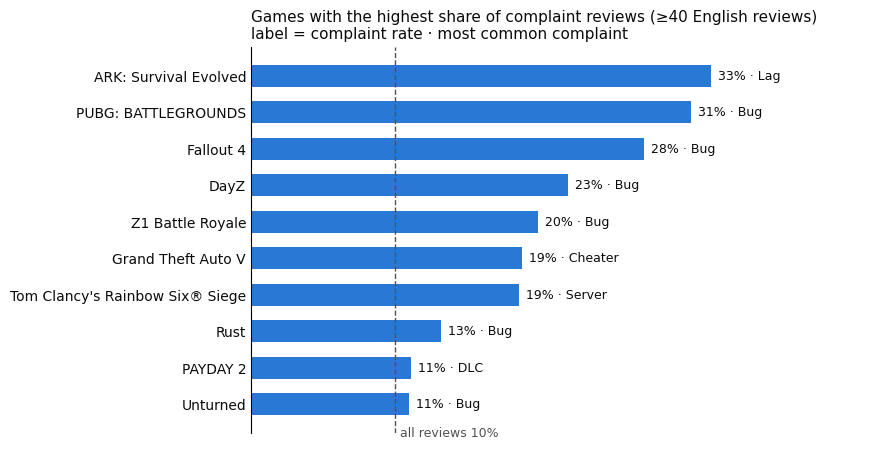

In [22]:
top = by_game.head(10).iloc[::-1]
overall = en["has_complaint"].mean()

fig, ax = plt.subplots(figsize=(9, 4.6))

ax.barh(top.index, top["complaint_rate"] * 100, color=BLUE, height=0.6)
ax.axvline(overall * 100, color=MUTED, linewidth=1, linestyle="--")
ax.text(overall * 100 + 0.4, -0.9, f"all reviews {overall:.0%}", color=MUTED, fontsize=9)

for y, (rate, category) in enumerate(zip(top["complaint_rate"], top["top_complaint"])):
    ax.text(rate * 100 + 0.5, y, f"{rate:.0%} · {category}", va="center", color=INK, fontsize=9)

ax.set_title(
    f"Games with the highest share of complaint reviews (≥{MIN_REVIEWS} English reviews)\n"
    "label = complaint rate · most common complaint",
    loc="left", color=INK, fontsize=11,
)
ax.set_xlim(0, top["complaint_rate"].max() * 100 + 12)
ax.set_xticks([])
ax.tick_params(colors=INK, length=0)
ax.spines[["top", "right", "bottom"]].set_visible(False)

fig.tight_layout()
fig.savefig(IMAGES_DIR / "04_complaints_by_game.png", dpi=160, bbox_inches="tight")
plt.show()

**Findings**
- About **1 in 10** English reviews contains a complaint; **Bug** is the most common category.
- Survival and battle-royale games (ARK, PUBG, DayZ, Z1) have the highest complaint rates; long-running
  Valve titles and finished single-player games (Portal 2, Undertale, Left 4 Dead 2) the lowest.
- The **type** of complaint differs by game: Counter-Strike reviews are dominated by **cheaters**,
  PAYDAY 2 by **DLC**, Rainbow Six Siege by **servers**, ARK by **performance (Lag)**. A single "risk score" would hide this.

## 8. Limitations and next steps

- **Labels:** 350 manually labelled reviews, one annotator. A second annotator would show how subjective the categories are.
- **Rules miss indirect complaints** (*"wish the price was lower"*), sarcasm and jokes (*"10/10 would crash again"*).
- **Next step:** use the labelled reviews to train or prompt a stronger model (zero-shot / LLM classification)
  and compare it on the same test set.
- Reviews span 2010–2018, so the results describe that period.